# Test your hospital

**What this notebook does.** You give it one hospital's four tables (`features`, `labels`, `predictions`, `embeddings`) and a trusted *reference* hospital (the one the AAA model was validated on). It then:

1. **Describes** the hospital: who the patients are, which scanners and protocols, how common aneurysms are.
2. **Checks for errors and corruption**: repeat patients, labels that follow a different rule, impossible values, missing model answers.
3. **Checks whether the hospital looks like the reference** (patients, scanners, scan content).
4. **Tests how good the AAA model is here**: sensitivity, specificity, balanced accuracy, G-mean, measurement error, with uncertainty and subgroup breakdowns.
5. **(Optional) Checks the aorta shapes** with pykarambola and comments on outline quality in plain language.
6. Saves everything to **one JSON file** (plus a one-page HTML report).

**How to use:** edit the CONFIG cell, then *Run All*. Every section ends with plain-language findings, collected at the end. Red = act before relying on the model, yellow = watch, ok = looks fine.

`monitor.py` must be in the same folder as this notebook.

In [217]:
import json, math, re, warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as st
import matplotlib.pyplot as plt
from scipy.sparse.csgraph import connected_components
from scipy.stats import binomtest, spearmanr
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.model_selection import GroupKFold, KFold, StratifiedGroupKFold, cross_val_predict, cross_val_score
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import HTML, display

import monitor   # monitor.py must sit next to this notebook

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

## 0. CONFIG: edit this cell only

In [218]:
# ----------------------------------------------------------------------------------
NEW_DIR        = Path("../../dataset/sunday/hospital_g")   # <-- CHANGE hospital_X to your hospital folder
HOSPITAL_NAME  = NEW_DIR.name                              # auto-derived from the folder name
REFERENCE_NAME = "hospital_a"                                # the trusted hospital the model was validated on
REFERENCE_DIR  = Path("../../dataset/practice/hospital_a")

# ---- optional shape analysis (pykarambola). Off by default because it is slow. ----
USE_SHAPE               = False   # True = add the aorta-shape / outline-quality section
SHAPE_FEATURES_FILE     = None    # e.g. Path(NEW_DIR / "karambola_features.parquet") if you already made it
MASK_DIR                = None    # e.g. Path(NEW_DIR / "masks") to compute shape features here (slow)
REF_SHAPE_FEATURES_FILE = None    # optional: the reference hospital's shape features, for comparison

OUT_DIR       = Path("hospital_test_output")
AAA_CUTOFF_MM = 30      # diameter rule the model follows for "aneurysm"
SIM_DUP       = 0.95    # embedding similarity above which two scans count as near-duplicates
N_JOBS        = 4       # parallel workers for shape extraction
# ----------------------------------------------------------------------------------
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = OUT_DIR / "figures"; FIG_DIR.mkdir(exist_ok=True)

## Helpers (collect findings and results as we go)

In [219]:
FINDINGS, RESULTS, FIGS = [], {}, []
CAT_COLS = monitor.CAT_COLS

def finding(area, severity, text, **evidence):
    """severity: 'red' = act before relying on the model, 'yellow' = watch, 'ok' = looks fine, 'info' = good to know"""
    FINDINGS.append({"area": area, "severity": severity, "text": text, "evidence": evidence})
    icon = {"red": "[RED]   ", "yellow": "[YELLOW]", "ok": "[OK]    ", "info": "[INFO]  "}[severity]
    print(f"{icon} {text}")

def show(fig, name):
    p = FIG_DIR / f"{HOSPITAL_NAME}_{name}.png"
    fig.savefig(p, dpi=120, bbox_inches="tight"); FIGS.append(str(p)); plt.show()

def to_float(s):
    return s.map(lambda v: np.nan if pd.isna(v) else float(bool(v))).astype(float)

def mix(df, col):
    return df[col].fillna("MISSING").astype(str).value_counts(normalize=True).sort_index()

def wilson(k, n):
    if n == 0: return np.nan, np.nan
    ci = binomtest(int(k), int(n)).proportion_ci(method="wilson")
    return float(ci.low), float(ci.high)

def clean(o):
    """Make anything JSON-safe (numpy -> python, NaN -> null)."""
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, set)): return [clean(v) for v in o]
    if isinstance(o, np.bool_): return bool(o)
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, (np.floating, float)): return None if (math.isnan(o) or math.isinf(o)) else float(o)
    if isinstance(o, pd.DataFrame): return clean(o.to_dict("records"))
    if isinstance(o, pd.Series): return clean(o.to_dict())
    if isinstance(o, (pd.Timestamp, datetime)): return o.isoformat()
    if isinstance(o, Path): return str(o)
    return o

def make_model(n):
    """The starter-script model: standardise -> PCA -> small neural network (diameter from embeddings)."""
    nc = int(max(2, min(32, n * 0.8 - 2)))
    return make_pipeline(StandardScaler(), PCA(nc, random_state=0),
                         MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, max_iter=3000, random_state=0))

## 1. Load the data and check the files

Each hospital folder needs `features.parquet`, `labels.parquet`, `predictions.parquet`, `embeddings.parquet`, all keyed by `case_id`.

In [220]:
EXPECTED_FEATURES = ["patient_id", "age_band", "sex", "scanner_vendor", "contrast_phase", "slice_thickness_mm",
                     "slice_thickness_class", "kvp", "aorta_hu_mean", "aorta_hu_sd", "organ_volumes_liver", "organ_volumes_spleen"]

def load_hospital(folder, name):
    folder = Path(folder)
    tabs = {}
    for t in ["features", "labels", "predictions", "embeddings"]:
        f = folder / f"{t}.parquet"
        if not f.exists():
            raise FileNotFoundError(f"{name}: missing {f}. Each hospital folder needs features, labels, predictions and embeddings .parquet files.")
        tabs[t] = pd.read_parquet(f)
    check = {"rows": {t: int(len(v)) for t, v in tabs.items()},
             "duplicate_case_ids": {t: int(v["case_id"].duplicated().sum()) for t, v in tabs.items()}}
    ids = {t: set(v["case_id"]) for t, v in tabs.items()}
    all_ids = set.union(*ids.values())
    check["case_ids_missing_from_file"] = {t: int(len(all_ids - ids[t])) for t in ids}
    df = (tabs["features"].drop_duplicates("case_id")
          .merge(tabs["labels"].drop_duplicates("case_id"), on="case_id")
          .merge(tabs["predictions"].drop_duplicates("case_id"), on="case_id", how="left")
          .merge(tabs["embeddings"].drop_duplicates("case_id"), on="case_id"))
    check["merged_rows"] = int(len(df))
    check["missing_expected_feature_columns"] = [c for c in EXPECTED_FEATURES if c not in df.columns]
    df["aaa"] = df["aaa"].astype(bool)
    df["aaa_f"] = df["aaa"].astype(float)
    df["pred_aaa_f"] = to_float(df["pred_aaa"])
    df["hospital"] = name
    return df.reset_index(drop=True), check

D, file_check = load_hospital(NEW_DIR, HOSPITAL_NAME)
R, ref_check = load_hospital(REFERENCE_DIR, REFERENCE_NAME)
emb_cols = [c for c in D if c.startswith("emb_")]
assert set(emb_cols) <= set(R.columns), "reference and new hospital use different embedding columns"
print(f"{HOSPITAL_NAME}: {len(D)} scans | reference {REFERENCE_NAME}: {len(R)} scans | embedding dims: {len(emb_cols)}")
print(json.dumps(file_check, indent=1))

RESULTS["files"] = {"new": file_check, "reference": ref_check}
if any(v > 0 for v in file_check["case_ids_missing_from_file"].values()):
    finding("Files", "yellow", "Some case_ids do not appear in all four files; scans missing from a file were dropped or left without predictions.",
            detail=file_check["case_ids_missing_from_file"])
if any(v > 0 for v in file_check["duplicate_case_ids"].values()):
    finding("Files", "red", "Some case_ids appear more than once inside a file.", detail=file_check["duplicate_case_ids"])
if file_check["missing_expected_feature_columns"]:
    finding("Files", "info", f"Columns not found: {file_check['missing_expected_feature_columns']}. Related checks are skipped.")
if len(D) < 50:
    finding("Files", "yellow", f"Only {len(D)} scans: every number below is rough, and subgroup results are very uncertain.")

hospital_g: 80 scans | reference hospital_a: 100 scans | embedding dims: 2048
{
 "rows": {
  "features": 80,
  "labels": 80,
  "predictions": 80,
  "embeddings": 80
 },
 "duplicate_case_ids": {
  "features": 0,
  "labels": 0,
  "predictions": 0,
  "embeddings": 0
 },
 "case_ids_missing_from_file": {
  "features": 0,
  "labels": 0,
  "predictions": 0,
  "embeddings": 0
 },
 "merged_rows": 80,
 "missing_expected_feature_columns": []
}


## 2. Describe the dataset

Who the patients are, which scanners and protocols were used, and how common aneurysms are, side by side with the reference hospital.

--- scanner_vendor (share of scans)
                hospital_g  hospital_a
scanner_vendor                        
MISSING               0.02        0.03
ge                    0.05        0.05
philips               0.10        0.04
siemens               0.82        0.88 

--- contrast_phase (share of scans)
                hospital_g  hospital_a
contrast_phase                        
arterial               0.1        0.14
non-contrast           0.3        0.26
venous                 0.6        0.60 

--- slice_thickness_class (share of scans)
                       hospital_g  hospital_a
slice_thickness_class                        
standard                     0.34        0.34
thick                        0.11        0.11
thin                         0.55        0.55 

--- sex (share of scans)
     hospital_g  hospital_a
sex                        
F          0.44        0.44
M          0.56        0.56 

--- age_band (share of scans)
          hospital_g  hospital_a
age_band          

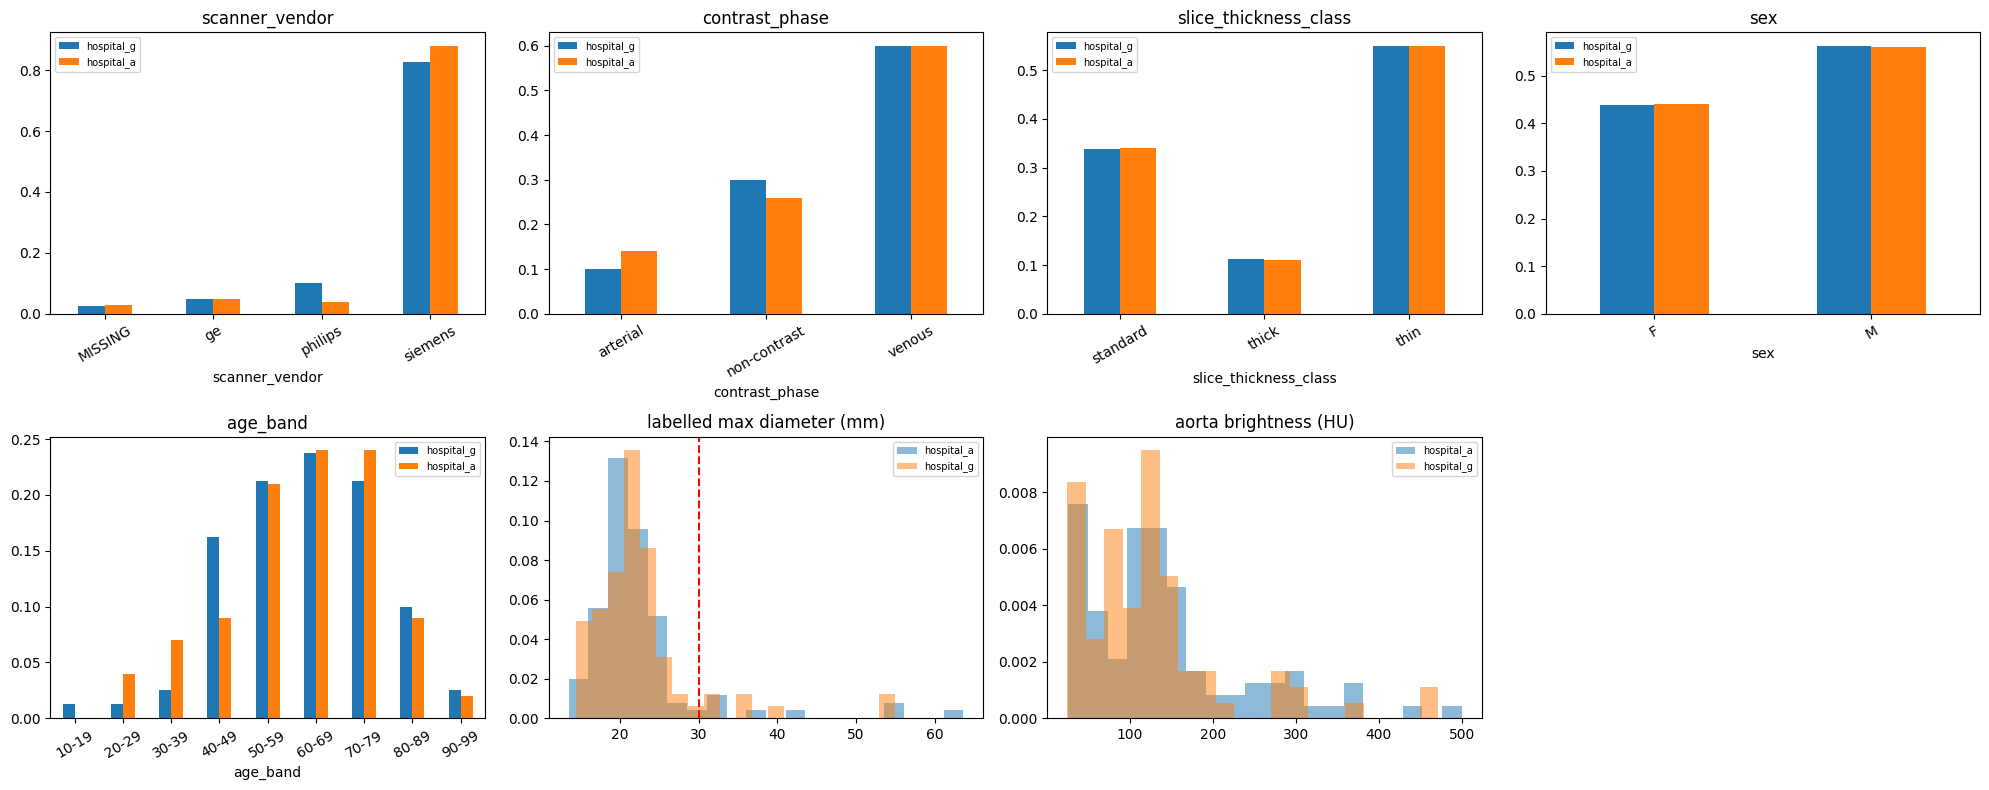

In [221]:
NUM_COLS = [c for c in ["kvp", "slice_thickness_mm", "aorta_hu_mean", "aorta_hu_sd", "organ_volumes_liver",
                        "organ_volumes_spleen", "organ_volumes_kidney_left", "organ_volumes_kidney_right"] if c in D]

def describe(df):
    d = df["max_aortic_diameter_mm"]
    out = {"n_scans": int(len(df)),
           "n_patient_ids": int(df["patient_id"].nunique()) if "patient_id" in df else None,
           "n_missing_patient_id": int(df["patient_id"].isna().sum()) if "patient_id" in df else None,
           "categorical": {c: mix(df, c).round(4).to_dict() for c in CAT_COLS if c in df},
           "numeric": {c: {"mean": df[c].mean(), "sd": df[c].std(), "min": df[c].min(), "median": df[c].median(),
                           "max": df[c].max(), "pct_missing": df[c].isna().mean()} for c in NUM_COLS},
           "labels": {"n_aaa": int(df["aaa"].sum()), "aaa_rate": float(df["aaa"].mean()),
                      "diameter_mean": d.mean(), "diameter_sd": d.std(), "diameter_min": d.min(),
                      "diameter_median": d.median(), "diameter_max": d.max(),
                      "size_class_mix": mix(df, "aaa_size_class").round(4).to_dict() if "aaa_size_class" in df else None}}
    return out

desc_new, desc_ref = describe(D), describe(R)

for c in CAT_COLS:
    if c in D:
        print(f"--- {c} (share of scans)")
        print(pd.concat({HOSPITAL_NAME: mix(D, c), REFERENCE_NAME: mix(R, c)}, axis=1).fillna(0).round(2).to_string(), "\n")
print("--- numeric features (mean / sd)")
print(pd.concat({HOSPITAL_NAME: D[NUM_COLS].agg(["mean", "std"]).T, REFERENCE_NAME: R[NUM_COLS].agg(["mean", "std"]).T}, axis=1).round(1).to_string())
print("\n--- labels")
print(pd.DataFrame({HOSPITAL_NAME: {k: v for k, v in desc_new["labels"].items() if k != "size_class_mix"},
                    REFERENCE_NAME: {k: v for k, v in desc_ref["labels"].items() if k != "size_class_mix"}}).round(2).to_string())

def top_level(df, col):
    if col not in df: return "n/a"
    m = mix(df, col).sort_values(ascending=False)
    return f"{m.index[0]} ({m.iloc[0]:.0%})"

summary_text = (f"{HOSPITAL_NAME} contributed {len(D)} scans from {desc_new['n_patient_ids']} patient IDs. "
                f"Most common scanner: {top_level(D, 'scanner_vendor')}; contrast phase: {top_level(D, 'contrast_phase')}; "
                f"slice thickness: {top_level(D, 'slice_thickness_class')}. Sex: {top_level(D, 'sex')}; most common age band: {top_level(D, 'age_band')}. "
                f"{int(D['aaa'].sum())} scans ({D['aaa'].mean():.0%}) carry an aneurysm label; the reference hospital has {R['aaa'].mean():.0%}.")
print("\nIn words:", summary_text)
RESULTS["dataset_description"] = {"summary_text": summary_text, "new": desc_new, "reference": desc_ref}

fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, [c for c in CAT_COLS if c in D]):
    pd.concat({HOSPITAL_NAME: mix(D, c), REFERENCE_NAME: mix(R, c)}, axis=1).fillna(0).plot.bar(ax=ax, rot=30)
    ax.set_title(c); ax.legend(fontsize=7)
for ax, c, lab in [(axes[5], "max_aortic_diameter_mm", "labelled max diameter (mm)"), (axes[6], "aorta_hu_mean", "aorta brightness (HU)")]:
    ax.hist(R[c].dropna(), bins=20, alpha=0.5, density=True, label=REFERENCE_NAME)
    ax.hist(D[c].dropna(), bins=20, alpha=0.5, density=True, label=HOSPITAL_NAME)
    ax.set_title(lab); ax.legend(fontsize=7)
axes[6].set_title("aorta brightness (HU)")
axes[5].axvline(AAA_CUTOFF_MM, color="r", ls="--")
axes[7].axis("off")
plt.tight_layout(); show(fig, "01_description")

## 3. Errors and corruption checks

The same checks that exposed the practice hospitals' problems: repeat patients, a split that leaks, labels that follow a different rule, impossible values, silent model non-answers.

### 3a. Is every scan a different patient? (repeat scans)
Embeddings of the same patient are nearly identical. We group scans that share a `patient_id` **or** have near-identical embeddings, so repeat scans filed under different IDs are caught too.

In [222]:
def patient_groups(df, thresh=SIM_DUP):
    """Group scans of the same real patient: same patient_id OR near-identical embedding."""
    Z = StandardScaler().fit_transform(df[emb_cols].to_numpy())
    Z = Z / np.maximum(np.linalg.norm(Z, axis=1, keepdims=True), 1e-9)
    S = Z @ Z.T
    np.fill_diagonal(S, -1)
    pid = (df["patient_id"].fillna(df["case_id"]) if "patient_id" in df else df["case_id"]).astype(str).to_numpy()
    same_pid = pid[:, None] == pid[None, :]
    _, lab = connected_components((S > thresh) | same_pid, directed=False)
    return lab, S, pid

lab_D, S_D, pid_D = patient_groups(D)
lab_R, S_R, pid_R = patient_groups(R)
twin, twin_sim = S_D.argmax(axis=1), S_D.max(axis=1)
is_dup = twin_sim > SIM_DUP
id_mismatch = is_dup & (pid_D != pid_D[twin])
n_true = len(set(lab_D))
keep_D = ~pd.Series(lab_D).duplicated().to_numpy()
keep_R = ~pd.Series(lab_R).duplicated().to_numpy()
Dd, Rd = D[keep_D].reset_index(drop=True), R[keep_R].reset_index(drop=True)   # one scan per real patient

diam = D["max_aortic_diameter_mm"].to_numpy()
twin_gap = np.abs(diam[is_dup] - diam[twin][is_dup])
dup_info = {"scans": int(len(D)), "patient_ids": int(len(set(pid_D))), "real_patients_after_dedupe": int(n_true),
            "scans_with_near_duplicate": int(is_dup.sum()), "share_with_near_duplicate": float(is_dup.mean()),
            "duplicates_under_different_patient_id": int(id_mismatch.sum()),
            "median_nearest_neighbour_similarity": float(np.median(twin_sim)),
            "median_diameter_gap_between_twins_mm": float(np.median(twin_gap)) if len(twin_gap) else None,
            "example_pairs": [[D["case_id"].iloc[i], D["case_id"].iloc[twin[i]]] for i in np.where(is_dup)[0][:10]],
            "reference_share_with_near_duplicate": float((S_R.max(axis=1) > SIM_DUP).mean())}
print(pd.Series({k: v for k, v in dup_info.items() if k != "example_pairs"}).to_string())

if is_dup.mean() > 0.01:
    finding("Repeat patients", "red",
            f"{is_dup.sum()} of {len(D)} scans ({is_dup.mean():.0%}) have a near-identical twin; there are only {n_true} real patients behind {len(D)} scans. "
            f"{id_mismatch.sum()} of the twins are filed under a different patient ID, so ID-based checks would miss them. "
            "Accuracy measured on this data will look better than it really is until repeats are removed.", **dup_info)
else:
    finding("Repeat patients", "ok", f"No repeat scans found: {len(D)} scans, {n_true} real patients.", **dup_info)
if D["patient_id"].isna().any():
    finding("Repeat patients", "yellow", f"{int(D['patient_id'].isna().sum())} scans have no patient_id, so repeat patients can only be found from the images.")
RESULTS["integrity"] = {"repeat_patients": dup_info}

scans                                    80.000000
patient_ids                              80.000000
real_patients_after_dedupe               80.000000
scans_with_near_duplicate                 0.000000
share_with_near_duplicate                 0.000000
duplicates_under_different_patient_id     0.000000
median_nearest_neighbour_similarity       0.528725
median_diameter_gap_between_twins_mm           NaN
reference_share_with_near_duplicate       0.000000
[OK]     No repeat scans found: 80 scans, 80 real patients.


### 3b. Does the score depend on how we split? (leakage test)
With repeat scans, a random split puts the same patient in both train and test, and the score measures memory, not skill. We train the starter model (diameter from embeddings) three ways. If the random split looks much better than the honest split, the data leaks.

In [223]:
Xe = D[emb_cols].to_numpy(); ye = D["max_aortic_diameter_mm"].to_numpy()
ok = ~np.isnan(ye)
splits = {"random split": (KFold(5, shuffle=True, random_state=0), None),
          "by listed patient_id": (GroupKFold(5), pid_D),
          "by real patient (after dedupe)": (GroupKFold(5), lab_D)}
leak = {}
for name, (cv, g) in splits.items():
    if g is not None and len(set(g[ok])) < 5:
        continue
    pr = cross_val_predict(make_model(len(D)), Xe[ok], ye[ok], cv=cv, groups=None if g is None else g[ok])
    leak[name] = {"MAE_mm": float(np.mean(np.abs(pr - ye[ok]))), "R2": float(1 - np.sum((pr - ye[ok]) ** 2) / np.sum((ye[ok] - ye[ok].mean()) ** 2))}
print(pd.DataFrame(leak).T.round(2).to_string())
honest, rand = leak.get("by real patient (after dedupe)"), leak.get("random split")
if honest and rand:
    gap = honest["MAE_mm"] - rand["MAE_mm"]
    if gap > 0.15 * honest["MAE_mm"]:
        finding("Leakage", "red", f"A random split gives {rand['MAE_mm']:.1f} mm error but the honest by-patient split gives {honest['MAE_mm']:.1f} mm: the data leaks, so random-split results here are too optimistic.", **leak)
    else:
        finding("Leakage", "ok", f"Random-split and by-patient errors agree ({rand['MAE_mm']:.1f} vs {honest['MAE_mm']:.1f} mm): no sign of leakage.", **leak)
finding("Leakage", "info", "R2 is unreliable with this few scans and a narrow diameter range; compare errors in mm and the random-vs-patient gap instead.")
RESULTS["integrity"]["leakage_test"] = leak

                                MAE_mm    R2
random split                      5.96 -0.51
by listed patient_id              4.89 -0.08
by real patient (after dedupe)    5.68 -0.45
[OK]     Random-split and by-patient errors agree (6.0 vs 5.7 mm): no sign of leakage.
[INFO]   R2 is unreliable with this few scans and a narrow diameter range; compare errors in mm and the random-vs-patient gap instead.


### 3c. Do the labels follow the same rule as the model? (labelling convention)

In [224]:
d = D["max_aortic_diameter_mm"]
neg_max = d[~D["aaa"]].max(); pos_min = d[D["aaa"]].min() if D["aaa"].any() else np.nan
ref_neg_max = R.loc[~R["aaa"], "max_aortic_diameter_mm"].max(); ref_pos_min = R.loc[R["aaa"], "max_aortic_diameter_mm"].min()
conflict = (d >= AAA_CUTOFF_MM) != D["aaa"]
lab_info = {"largest_diameter_labelled_not_aaa": neg_max, "smallest_diameter_labelled_aaa": pos_min,
            "reference_largest_not_aaa": ref_neg_max, "reference_smallest_aaa": ref_pos_min,
            "n_labels_disagreeing_with_cutoff": int(conflict.sum()), "share_disagreeing": float(conflict.mean()),
            "cutoff_mm": AAA_CUTOFF_MM}

size_mismatch = None
if "aaa_size_class" in D and set(D["aaa_size_class"].dropna().unique()) <= {"none", "30-54mm", ">=55mm"}:
    exp = d.map(lambda x: "none" if x < 30 else ("30-54mm" if x < 55 else ">=55mm"))
    size_mismatch = int((exp != D["aaa_size_class"]).sum()); lab_info["n_size_class_disagreeing_with_diameter"] = size_mismatch
print(pd.Series(lab_info).round(1).to_string())

if conflict.mean() > 0.05 or (not np.isnan(pos_min) and pos_min < AAA_CUTOFF_MM - 3):
    finding("Labelling", "red",
            f"This hospital labels an aneurysm from {pos_min:.1f} mm (reference: {ref_pos_min:.1f} mm) and {conflict.sum()} labels ({conflict.mean():.0%}) disagree with the {AAA_CUTOFF_MM} mm rule the model follows. "
            "The model's AAA calls cannot be judged until both sides use the same definition.", **lab_info)
elif conflict.mean() > 0.02:
    finding("Labelling", "yellow", f"{conflict.sum()} labels ({conflict.mean():.0%}) disagree with the {AAA_CUTOFF_MM} mm rule.", **lab_info)
else:
    finding("Labelling", "ok", f"Aneurysm labels follow the {AAA_CUTOFF_MM} mm rule (largest 'no AAA' {neg_max:.1f} mm, smallest 'AAA' {pos_min:.1f} mm).", **lab_info)
if size_mismatch:
    finding("Labelling", "yellow", f"{size_mismatch} scans have a size class that does not match their own diameter.")

# ---- impossible / suspicious values ----
ranges = {"max_aortic_diameter_mm": (8, 120), "pred_max_diameter_mm": (8, 120), "aorta_hu_mean": (-150, 1000),
          "kvp": (70, 150), "slice_thickness_mm": (0.1, 10)}
implausible = {c: int(((D[c] < lo) | (D[c] > hi)).sum()) for c, (lo, hi) in ranges.items() if c in D}
for c in [c for c in D if c.startswith("organ_volumes_")]:
    implausible[c + " (negative)"] = int((D[c] < 0).sum())
implausible = {k: v for k, v in implausible.items() if v}
if implausible:
    finding("Impossible values", "red", f"Values outside any plausible range: {implausible}.", detail=implausible)
else:
    finding("Impossible values", "ok", "No impossible diameters, brightness, kVp, slice thickness or organ volumes.")
RESULTS["integrity"]["labelling"] = lab_info
RESULTS["integrity"]["implausible_values"] = implausible

largest_diameter_labelled_not_aaa         29.9
smallest_diameter_labelled_aaa            31.5
reference_largest_not_aaa                 28.2
reference_smallest_aaa                    30.2
n_labels_disagreeing_with_cutoff           0.0
share_disagreeing                          0.0
cutoff_mm                                 30.0
n_size_class_disagreeing_with_diameter     0.0
[OK]     Aneurysm labels follow the 30 mm rule (largest 'no AAA' 29.9 mm, smallest 'AAA' 31.5 mm).
[OK]     No impossible diameters, brightness, kVp, slice thickness or organ volumes.


### 3d. Does the supplied model disagree with the labels in odd ways? And does it ever stay silent?

In [225]:
D["base_err"] = D["pred_max_diameter_mm"] - D["max_aortic_diameter_mm"]
R["base_err"] = R["pred_max_diameter_mm"] - R["max_aortic_diameter_mm"]
sd_ref = R["base_err"].std()
outl = D["base_err"].abs() > 3 * sd_ref
na_rate = D["pred_aaa_f"].isna().mean()
silent = {}
for c in ["contrast_phase", "sex", "scanner_vendor", "slice_thickness_class"]:
    if c in D:
        t = D.assign(_g=D[c].fillna("MISSING")).groupby("_g")["pred_aaa_f"].agg(lambda s: s.isna().mean())
        silent[c] = {str(k): float(v) for k, v in t.items() if v > 0}
pred_info = {"share_no_answer": float(na_rate), "reference_share_no_answer": float(R["pred_aaa_f"].isna().mean()),
             "n_diameter_outliers_vs_label": int(outl.sum()), "outlier_threshold_mm": float(3 * sd_ref),
             "outlier_case_ids": D.loc[outl, "case_id"].head(15).tolist(), "no_answer_by_group": silent}
print(json.dumps(pred_info, indent=1))
if na_rate > 0.04:
    finding("Silent failures", "red", f"The model returned no AAA answer for {na_rate:.0%} of scans, most often in: {silent}. A blank must never be read as 'normal'.", **pred_info)
elif na_rate > 0.02:
    finding("Silent failures", "yellow", f"The model returned no AAA answer for {na_rate:.0%} of scans.", **pred_info)
else:
    finding("Silent failures", "ok", f"The model answered for {1 - na_rate:.0%} of scans.")
if outl.sum():
    finding("Measurement outliers", "yellow", f"{outl.sum()} scan(s) where the model's diameter differs from the label by more than {3 * sd_ref:.1f} mm (3x the reference spread). Worth a manual look.", ids=pred_info["outlier_case_ids"])
RESULTS["integrity"]["model_outputs"] = pred_info

{
 "share_no_answer": 0.0125,
 "reference_share_no_answer": 0.0,
 "n_diameter_outliers_vs_label": 1,
 "outlier_threshold_mm": 4.26681928709678,
 "outlier_case_ids": [
  "38b19a6975e23313"
 ],
 "no_answer_by_group": {
  "contrast_phase": {
   "non-contrast": 0.041666666666666664
  },
  "sex": {
   "F": 0.02857142857142857
  },
  "scanner_vendor": {
   "siemens": 0.015151515151515152
  },
  "slice_thickness_class": {
   "thin": 0.022727272727272728
  }
 }
}
[OK]     The model answered for 99% of scans.
[YELLOW] 1 scan(s) where the model's diameter differs from the label by more than 4.3 mm (3x the reference spread). Worth a manual look.


## 4. Does this hospital look like the reference?

Compared on **patients and scanners** (mix of categories, brightness, diameters), on **scan content** (does a classifier on the embeddings tell the two hospitals apart? how many scans are far from anything in the reference?). Numeric tests use one scan per real patient and a permutation test, so a difference is only called real if it beats chance.

In [226]:
def gaps(c, k=2):
    a, b = mix(D, c), mix(R, c)
    idx = a.index.union(b.index)
    diff = (a.reindex(idx, fill_value=0) - b.reindex(idx, fill_value=0))
    top = diff.abs().sort_values(ascending=False).index[:k]
    return "; ".join(f"{i}: {a.get(i, 0):.0%} here vs {b.get(i, 0):.0%} reference" for i in top)

shift = {"categorical_distance": {}, "numeric": {}}
for c in CAT_COLS:
    if c not in D: continue
    t = float(monitor.tvd(mix(D, c), mix(R, c)))
    shift["categorical_distance"][c] = round(t, 3)
    label = monitor.CAT_LABEL[c].lower()
    if t > 0.30:   finding("Patients & scanners", "red", f"The {label} is very different from the reference (distance {t:.2f}). {gaps(c)}.", distance=t)
    elif t > 0.15: finding("Patients & scanners", "yellow", f"The {label} differs from the reference (distance {t:.2f}). {gaps(c)}.", distance=t)
print("category distance (0 = identical, 1 = nothing in common):", shift["categorical_distance"])

def w_test(x, y, n_perm=1000, seed=0):
    x, y = np.asarray(x, float), np.asarray(y, float)
    x, y = x[~np.isnan(x)], y[~np.isnan(y)]
    if len(x) < 5 or len(y) < 5: return {"sd_units": np.nan, "p": np.nan, "median_diff": np.nan, "null95_sd_units": np.nan}
    rng = np.random.default_rng(seed)
    obs = st.wasserstein_distance(x, y); pool = np.concatenate([x, y]); n = len(x)
    null = np.empty(n_perm)
    for i in range(n_perm):
        rng.shuffle(pool); null[i] = st.wasserstein_distance(pool[:n], pool[n:])
    return {"sd_units": obs / np.std(y), "p": (1 + (null >= obs).sum()) / (n_perm + 1),
            "median_diff": np.median(x) - np.median(y), "null95_sd_units": np.percentile(null, 95) / np.std(y)}

NICE = {"aorta_hu_mean": "aorta brightness (HU)", "max_aortic_diameter_mm": "labelled aorta diameter",
        "pred_max_diameter_mm": "predicted aorta diameter", "kvp": "tube voltage (kVp)", "slice_thickness_mm": "slice thickness"}
for c, nice in NICE.items():
    if c in Dd:
        r = w_test(Dd[c], Rd[c]); shift["numeric"][c] = r
        if r["p"] < 0.01 and r["sd_units"] > 0.5:   finding("Patients & scanners", "red", f"The {nice} is clearly different from the reference (shift {r['sd_units']:.2f} SD, median {r['median_diff']:+.1f}, p={r['p']:.3f}).", **r)
        elif r["p"] < 0.05 and r["sd_units"] > 0.25: finding("Patients & scanners", "yellow", f"The {nice} is somewhat different from the reference (shift {r['sd_units']:.2f} SD, p={r['p']:.3f}).", **r)
print(pd.DataFrame(shift["numeric"]).T.round(3).to_string())

# aneurysm prevalence
a_new, a_ref = int(Dd["aaa"].sum()), int(Rd["aaa"].sum())
odds, p_f = st.fisher_exact([[a_new, len(Dd) - a_new], [a_ref, len(Rd) - a_ref]])
shift["aaa_prevalence"] = {"new": a_new / len(Dd), "reference": a_ref / len(Rd), "fisher_p": float(p_f)}
if p_f < 0.05 and abs(a_new / len(Dd) - a_ref / len(Rd)) > 0.05:
    finding("Patients & scanners", "yellow", f"Aneurysm prevalence is {a_new / len(Dd):.0%} here vs {a_ref / len(Rd):.0%} at the reference (p={p_f:.3f}); the model sees a different case mix.", **shift["aaa_prevalence"])

category distance (0 = identical, 1 = nothing in common): {'scanner_vendor': 0.06, 'contrast_phase': 0.04, 'slice_thickness_class': 0.003, 'sex': 0.002, 'age_band': 0.103}
                        sd_units      p  median_diff  null95_sd_units
aorta_hu_mean              0.196  0.285      -10.561            0.300
max_aortic_diameter_mm     0.088  0.986        0.467            0.297
pred_max_diameter_mm       0.104  0.940        0.330            0.288
kvp                        0.200  0.345        0.000            0.321
slice_thickness_mm         0.124  0.618        0.000            0.315


In [227]:
# ---- scan-content shift: classifier on embeddings + coverage of the reference ----
def domain_auc(Xa, Xb, ga, gb, n_pc=32):
    X = np.vstack([Xa, Xb]); y = np.r_[np.zeros(len(Xa)), np.ones(len(Xb))]; g = np.r_[ga, gb]
    Zp = StandardScaler().fit_transform(X)
    Zp = PCA(min(n_pc, len(X) - 2, Zp.shape[1]), random_state=0).fit_transform(Zp)
    cv = StratifiedGroupKFold(5, shuffle=True, random_state=0)
    return float(cross_val_score(LogisticRegression(max_iter=2000), Zp, y, groups=g, cv=cv, scoring="roc_auc").mean())

auc = domain_auc(R[emb_cols].to_numpy(), D[emb_cols].to_numpy(), np.array([f"ref_{i}" for i in lab_R]), np.array([f"new_{i}" for i in lab_D]))
prof = monitor.fit_reference(R, name=REFERENCE_NAME)
Xn = prof["pca"].transform(prof["scaler"].transform(D[emb_cols].to_numpy()))
dist, _ = prof["nn"].kneighbors(Xn, n_neighbors=prof["k"])
outside = float((dist.mean(axis=1) > prof["dist_thr"]).mean())
shift["scan_content"] = {"domain_classifier_auc": auc, "share_outside_reference_coverage": outside, "reference_baseline_share": 0.05}
print(f"classifier AUC telling {HOSPITAL_NAME} from {REFERENCE_NAME}: {auc:.2f}  (0.5 = indistinguishable)")
print(f"scans outside the reference's coverage: {outside:.0%}  (the reference itself is 5% by construction)")

if auc >= 0.80:  finding("Scan content", "red", f"A simple classifier can tell this hospital's scans from the reference with AUC {auc:.2f}; the images are systematically different.", auc=auc)
elif auc >= 0.65: finding("Scan content", "yellow", f"The scans are partly distinguishable from the reference (AUC {auc:.2f}).", auc=auc)
else: finding("Scan content", "ok", f"The scans are hard to tell apart from the reference (AUC {auc:.2f}).", auc=auc)
if outside > 0.20:   finding("Scan content", "red", f"{outside:.0%} of scans look unlike anything the model was validated on.", share=outside)
elif outside > 0.10: finding("Scan content", "yellow", f"{outside:.0%} of scans look unlike anything in the reference.", share=outside)
RESULTS["shift_vs_reference"] = shift

classifier AUC telling hospital_g from hospital_a: 0.52  (0.5 = indistinguishable)
scans outside the reference's coverage: 4%  (the reference itself is 5% by construction)
[OK]     The scans are hard to tell apart from the reference (AUC 0.52).


## 5. How good is the AAA model at this hospital?

The model returns a **diameter** and a yes/no **AAA call** for each scan. We score both against the hospital's labels.

* **Sensitivity**: of the real aneurysms, how many did it catch.
* **Specificity**: of the scans without aneurysm, how many did it correctly clear.
* **Balanced accuracy** = average of the two (0.5 = coin flip). **G-mean** = square root of their product (drops to 0 if either side is missed completely).
* Every sensitivity comes with a **95% range**, because a hospital with 7 aneurysms cannot support a precise number.
* A scan where the model gave **no answer** counts as a miss ("missing = wrong"). We also show accuracy *when it answered*.

In [228]:
def bin_metrics(g, missing="wrong"):
    y = g["aaa"].to_numpy(bool); p = g["pred_aaa_f"].to_numpy(float)
    if missing == "drop":
        keep = ~np.isnan(p); y, p = y[keep], p[keep]
    pos, neg = int(y.sum()), int((~y).sum())
    tp = int((y & (p == 1)).sum()); tn = int((~y & (p == 0)).sum())
    sens = tp / pos if pos else np.nan; spec = tn / neg if neg else np.nan
    (slo, shi), (plo, phi) = wilson(tp, pos), wilson(tn, neg)
    ok_ = not (np.isnan(sens) or np.isnan(spec))
    return {"n": int(len(y)), "n_aaa": pos, "n_not_aaa": neg, "tp": tp, "fn": pos - tp, "tn": tn, "fp": neg - tn,
            "n_no_answer": int(np.isnan(g["pred_aaa_f"].to_numpy(float)).sum()) if missing == "wrong" else 0,
            "sens": sens, "sens_lo": slo, "sens_hi": shi, "spec": spec, "spec_lo": plo, "spec_hi": phi,
            "bal_acc": (sens + spec) / 2 if ok_ else np.nan, "g_mean": float(np.sqrt(sens * spec)) if ok_ else np.nan}

def diam_metrics(g):
    m = g["pred_max_diameter_mm"].notna() & g["max_aortic_diameter_mm"].notna()
    e = (g.loc[m, "pred_max_diameter_mm"] - g.loc[m, "max_aortic_diameter_mm"]).to_numpy(float)
    if len(e) < 3:
        return {"n": int(len(e)), "mae": np.nan, "rmse": np.nan, "bias": np.nan, "loa_low": np.nan, "loa_high": np.nan,
                "within_2mm": np.nan, "within_3mm": np.nan, "spearman": np.nan}
    return {"n": int(len(e)), "mae": float(np.abs(e).mean()), "rmse": float(np.sqrt((e ** 2).mean())), "bias": float(e.mean()),
            "loa_low": float(e.mean() - 1.96 * e.std()), "loa_high": float(e.mean() + 1.96 * e.std()),
            "within_2mm": float((np.abs(e) <= 2).mean()), "within_3mm": float((np.abs(e) <= 3).mean()),
            "spearman": float(spearmanr(g.loc[m, "pred_max_diameter_mm"], g.loc[m, "max_aortic_diameter_mm"])[0])}

def dice_metrics(g):
    x = g["pred_aorta_dice"].dropna() if "pred_aorta_dice" in g else pd.Series(dtype=float)
    if not len(x): return {}
    return {"median": float(x.median()), "mean": float(x.mean()), "share_below_0.90": float((x < 0.90).mean()), "share_below_0.85": float((x < 0.85).mean())}

perf = {"new": {"aaa_call_missing_as_wrong": bin_metrics(D), "aaa_call_when_answered": bin_metrics(D, "drop"),
                "diameter": diam_metrics(D), "outline_dice": dice_metrics(D)},
        "reference": {"aaa_call_missing_as_wrong": bin_metrics(R), "aaa_call_when_answered": bin_metrics(R, "drop"),
                      "diameter": diam_metrics(R), "outline_dice": dice_metrics(R)}}

show_cols = ["n", "n_aaa", "tp", "sens", "sens_lo", "sens_hi", "spec", "bal_acc", "g_mean", "n_no_answer"]
tab = pd.DataFrame({f"{HOSPITAL_NAME} (missing=wrong)": perf["new"]["aaa_call_missing_as_wrong"],
                    f"{HOSPITAL_NAME} (when answered)": perf["new"]["aaa_call_when_answered"],
                    f"{REFERENCE_NAME} (missing=wrong)": perf["reference"]["aaa_call_missing_as_wrong"]}).loc[show_cols]
print("=== AAA yes/no call ===\n", tab.round(2).to_string())
print("\n=== diameter measurement (mm) ===\n", pd.DataFrame({HOSPITAL_NAME: perf["new"]["diameter"], REFERENCE_NAME: perf["reference"]["diameter"]}).round(2).to_string())
print("\n=== outline overlap with the expert outline (Dice) ===\n", pd.DataFrame({HOSPITAL_NAME: perf["new"]["outline_dice"], REFERENCE_NAME: perf["reference"]["outline_dice"]}).round(3).to_string())

b, br, dm, dr = perf["new"]["aaa_call_missing_as_wrong"], perf["reference"]["aaa_call_missing_as_wrong"], perf["new"]["diameter"], perf["reference"]["diameter"]
if b["n_aaa"] < 3:
    finding("AAA model", "info", f"Only {b['n_aaa']} scans carry an aneurysm label, too few to judge the model's AAA call.")
else:
    msg = (f"The model caught {b['tp']} of {b['n_aaa']} aneurysms (sensitivity {b['sens']:.0%}, plausible range {b['sens_lo']:.0%} to {b['sens_hi']:.0%}; "
           f"reference {br['sens']:.0%}). Balanced accuracy {b['bal_acc']:.2f}, G-mean {b['g_mean']:.2f}.")
    sev = "red" if b["sens_hi"] < 0.70 else ("yellow" if b["sens"] < 0.80 else "ok")
    finding("AAA model", sev, msg, **b)
if b["spec"] < 0.90: finding("AAA model", "yellow", f"The model raised false alarms: specificity {b['spec']:.0%} ({b['fp']} of {b['n_not_aaa']} healthy scans, including no-answers).", **b)
sev = "red" if dm["mae"] > 3 else ("yellow" if dm["mae"] > 2 else "ok")
finding("AAA model", sev, f"Diameter error: on average {dm['mae']:.1f} mm (reference {dr['mae']:.1f} mm); {dm['within_2mm']:.0%} of scans within 2 mm; bias {dm['bias']:+.1f} mm.", **dm)
RESULTS["model_performance"] = perf

=== AAA yes/no call ===
              hospital_g (missing=wrong)  hospital_g (when answered)  hospital_a (missing=wrong)
n                                 80.00                       79.00                      100.00
n_aaa                              7.00                        7.00                        9.00
tp                                 7.00                        7.00                        8.00
sens                               1.00                        1.00                        0.89
sens_lo                            0.65                        0.65                        0.57
sens_hi                            1.00                        1.00                        0.98
spec                               0.99                        1.00                        1.00
bal_acc                            0.99                        1.00                        0.94
g_mean                             0.99                        1.00                        0.94
n_no_answer    

In [229]:
# ---- by subgroup: does the model work equally well for everyone? ----
SUBGROUPS = [c for c in ["contrast_phase", "slice_thickness_class", "sex", "age_band", "scanner_vendor"] if c in D]

def subgroup_table(df, col):
    rows = []
    for lvl, g in df.assign(_g=df[col].fillna("MISSING")).groupby("_g"):
        b_, d_ = bin_metrics(g), diam_metrics(g)
        rows.append({"variable": col, "level": str(lvl), "n": b_["n"], "n_aaa": b_["n_aaa"], "sens": b_["sens"], "sens_lo": b_["sens_lo"],
                     "sens_hi": b_["sens_hi"], "spec": b_["spec"], "bal_acc": b_["bal_acc"], "g_mean": b_["g_mean"],
                     "mae_mm": d_["mae"], "bias_mm": d_["bias"], "pct_no_answer": float(g["pred_aaa_f"].isna().mean())})
    return pd.DataFrame(rows)

sub = pd.concat([subgroup_table(D, c) for c in SUBGROUPS], ignore_index=True)
ref_mae = dr["mae"]
def flag_row(r):
    f = []
    if r["n"] >= 15 and r["mae_mm"] > max(2.0, 2 * ref_mae): f.append("measurement error high")
    if r["n_aaa"] >= 3 and r["sens_hi"] < 0.70: f.append("misses aneurysms")
    if r["n"] >= 15 and r["pct_no_answer"] > 0.04: f.append("many no-answers")
    return "; ".join(f)
sub["flags"] = sub.apply(flag_row, axis=1)
print(sub.round(2).to_string(index=False))

# one finding per problem type (not one per subgroup), so a hospital-wide problem is not repeated 10 times
for flag_name, eligible in [("measurement error high", sub["n"] >= 15), ("misses aneurysms", sub["n_aaa"] >= 3), ("many no-answers", sub["n"] >= 15)]:
    hit = sub[sub["flags"].str.contains(flag_name)]
    if not len(hit): continue
    names = [f"{r['variable']}={r['level']} (n={r['n']})" for _, r in hit.iterrows()]
    everywhere = len(hit) >= 0.8 * max(int(eligible.sum()), 1)
    listing = ", ".join(names[:8]) + (" ..." if len(names) > 8 else "")
    if everywhere:
        finding("Subgroups", "yellow", f"Problem '{flag_name}' appears in nearly every subgroup tested ({len(hit)} of {int(eligible.sum())}), so it is hospital-wide, not specific to one scanner or patient group.", groups=names)
    else:
        finding("Subgroups", "yellow", f"Problem '{flag_name}' in: {listing}.", groups=names)
gaps_ = sub[(sub["n"] >= 10) & (sub["n_aaa"] == 0)]
evidence_gaps = [f"{r['variable']}={r['level']}" for _, r in gaps_.iterrows()]
if evidence_gaps:
    finding("Subgroups", "info", f"No aneurysm cases in these groups, so the model's AAA detection there could not be tested: {', '.join(evidence_gaps)}.", groups=evidence_gaps)
small = sub[(sub["n_aaa"] > 0) & (sub["n_aaa"] < 3)]
if len(small): finding("Subgroups", "info", "Subgroups with only 1-2 aneurysms give meaningless sensitivity numbers; they are listed but should not be interpreted.")
RESULTS["model_performance"]["subgroups"] = sub
RESULTS["model_performance"]["evidence_gaps"] = evidence_gaps

             variable        level  n  n_aaa  sens  sens_lo  sens_hi  spec  bal_acc  g_mean  mae_mm  bias_mm  pct_no_answer           flags
       contrast_phase     arterial  8      2   1.0     0.34      1.0  1.00     1.00    1.00    0.64    -0.36           0.00                
       contrast_phase non-contrast 24      0   NaN      NaN      NaN  0.96      NaN     NaN    0.56    -0.21           0.04 many no-answers
       contrast_phase       venous 48      5   1.0     0.57      1.0  1.00     1.00    1.00    0.60    -0.29           0.00                
slice_thickness_class     standard 27      3   1.0     0.44      1.0  1.00     1.00    1.00    0.73    -0.32           0.00                
slice_thickness_class        thick  9      0   NaN      NaN      NaN  1.00      NaN     NaN    0.20     0.04           0.00                
slice_thickness_class         thin 44      4   1.0     0.51      1.0  0.98     0.99    0.99    0.58    -0.31           0.02                
                  se

cutoff on the model's predicted diameter that best reproduces the labels:
  this hospital : {'low': 30.0, 'high': 30.5, 'bal_acc_at_best': 1.0}
  reference     : {'low': 27.0, 'high': 29.0, 'bal_acc_at_best': 0.9945054945054945}
[YELLOW] The labels line up with the model's diameters at 30.0-30.5 mm, versus 27.0-29.0 mm at the reference.


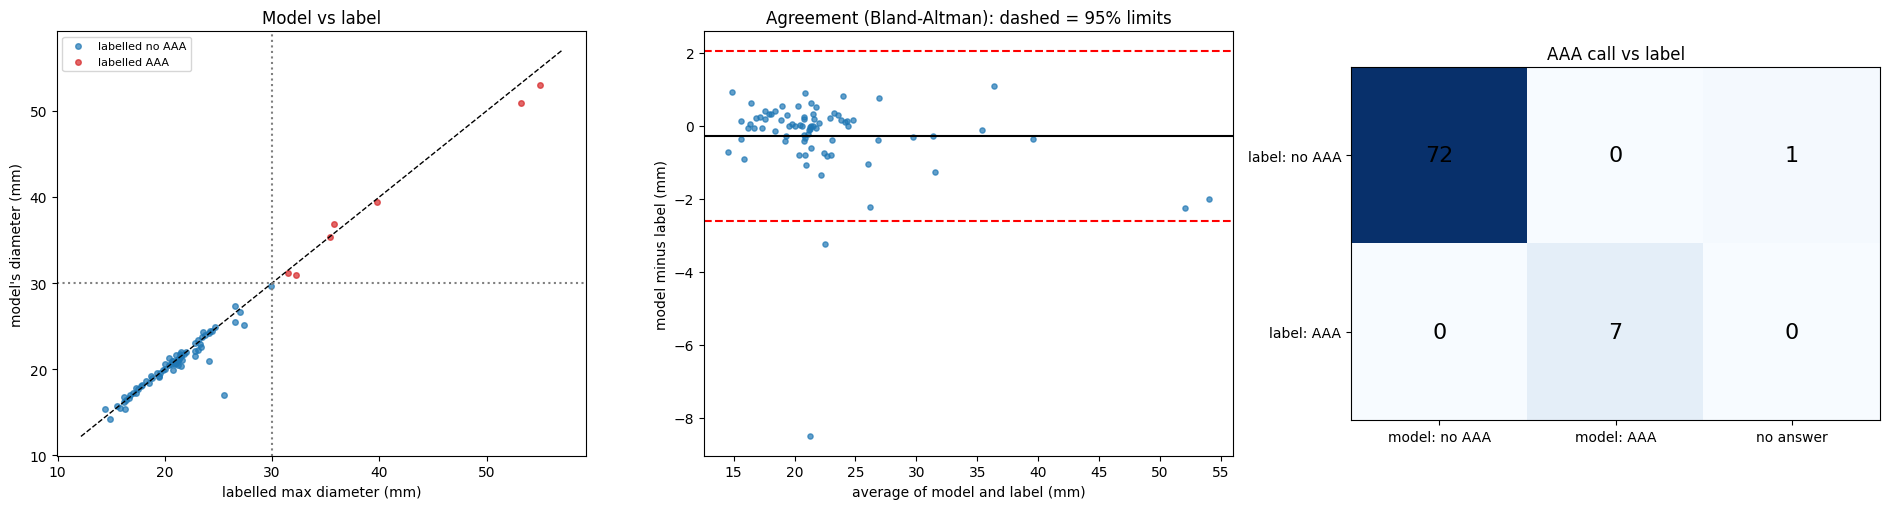

In [230]:
# ---- which diameter cutoff does the model effectively apply, compared with this hospital's labels? ----
def cutoff_range(df, grid=np.arange(20, 40.01, 0.5)):
    m = df["pred_max_diameter_mm"].notna()
    y = df.loc[m, "aaa"].to_numpy(bool); dd = df.loc[m, "pred_max_diameter_mm"].to_numpy(float)
    if y.sum() == 0 or (~y).sum() == 0: return None
    sc = np.array([(((dd >= t) & y).sum() / y.sum() + ((dd < t) & ~y).sum() / (~y).sum()) / 2 for t in grid])
    okg = grid[sc >= sc.max() - 1e-9]
    return {"low": float(okg.min()), "high": float(okg.max()), "bal_acc_at_best": float(sc.max())}

cut_new, cut_ref = cutoff_range(D), cutoff_range(R)
print("cutoff on the model's predicted diameter that best reproduces the labels:")
print("  this hospital :", cut_new); print("  reference     :", cut_ref)
def rng_txt(c): return f"{c['low']:.1f} mm" if c["low"] == c["high"] else f"{c['low']:.1f}-{c['high']:.1f} mm"
if cut_new and cut_ref:
    shift_mm = (cut_new["low"] + cut_new["high"]) / 2 - (cut_ref["low"] + cut_ref["high"]) / 2
    if abs(shift_mm) >= 3:
        finding("Labelling vs model", "red", f"The model's diameter output matches this hospital's AAA labels best at {rng_txt(cut_new)}, versus {rng_txt(cut_ref)} at the reference: the hospital's definition of an aneurysm differs from the model's. The model measures well but its yes/no call will not match.", **cut_new)
    elif abs(shift_mm) >= 2:
        finding("Labelling vs model", "yellow", f"The labels line up with the model's diameters at {rng_txt(cut_new)}, versus {rng_txt(cut_ref)} at the reference.", **cut_new)
    else:
        finding("Labelling vs model", "ok", "This hospital's labels line up with the model's diameter output at about the same cutoff as the reference.")
RESULTS["model_performance"]["effective_cutoff"] = {"new": cut_new, "reference": cut_ref}

# ---- pictures ----
fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))
m = D["pred_max_diameter_mm"].notna()
for flag, col, lab in [(False, "tab:blue", "labelled no AAA"), (True, "tab:red", "labelled AAA")]:
    mm = m & (D["aaa"] == flag)
    ax[0].scatter(D.loc[mm, "max_aortic_diameter_mm"], D.loc[mm, "pred_max_diameter_mm"], s=16, c=col, alpha=0.7, label=lab)
lim = [min(D["max_aortic_diameter_mm"].min(), D["pred_max_diameter_mm"].min()) - 2, max(D["max_aortic_diameter_mm"].max(), D["pred_max_diameter_mm"].max()) + 2]
ax[0].plot(lim, lim, "k--", lw=1); ax[0].axvline(AAA_CUTOFF_MM, color="grey", ls=":"); ax[0].axhline(AAA_CUTOFF_MM, color="grey", ls=":")
ax[0].set_xlabel("labelled max diameter (mm)"); ax[0].set_ylabel("model's diameter (mm)"); ax[0].set_title("Model vs label"); ax[0].legend(fontsize=8)
e = (D["pred_max_diameter_mm"] - D["max_aortic_diameter_mm"])[m]; avg = ((D["pred_max_diameter_mm"] + D["max_aortic_diameter_mm"]) / 2)[m]
ax[1].scatter(avg, e, s=14, alpha=0.7); ax[1].axhline(e.mean(), color="k"); ax[1].axhline(e.mean() + 1.96 * e.std(), color="r", ls="--"); ax[1].axhline(e.mean() - 1.96 * e.std(), color="r", ls="--")
ax[1].set_xlabel("average of model and label (mm)"); ax[1].set_ylabel("model minus label (mm)"); ax[1].set_title("Agreement (Bland-Altman): dashed = 95% limits")
p_ = D["pred_aaa_f"]
cmx = np.array([[((~D["aaa"]) & (p_ == 0)).sum(), ((~D["aaa"]) & (p_ == 1)).sum(), ((~D["aaa"]) & p_.isna()).sum()],
                [(D["aaa"] & (p_ == 0)).sum(), (D["aaa"] & (p_ == 1)).sum(), (D["aaa"] & p_.isna()).sum()]])
ax[2].imshow(cmx, cmap="Blues")
for (i, j), v in np.ndenumerate(cmx): ax[2].text(j, i, int(v), ha="center", va="center", fontsize=16)
ax[2].set_xticks([0, 1, 2]); ax[2].set_xticklabels(["model: no AAA", "model: AAA", "no answer"]); ax[2].set_yticks([0, 1]); ax[2].set_yticklabels(["label: no AAA", "label: AAA"])
ax[2].set_title("AAA call vs label")
plt.tight_layout(); show(fig, "03_model_performance")

## 6. What do the embeddings know? (embeddings vs labels and features)

The embeddings are the model-independent "fingerprint" of each scan. This section asks which labels and features can be read back out of them, in this hospital. If they encode **scanner, slice thickness or contrast phase** more strongly than **disease**, a model built on them can pick up shortcuts instead of anatomy.

How well each variable can be read back from the embeddings (balanced accuracy vs chance):
                       balanced_accuracy  chance
contrast_phase                      0.78    0.50
slice_thickness_class               0.62    0.50
sex                                 0.88    0.50
age_band                            0.42    0.25

R2 for continuous variables: {'max_aortic_diameter_mm': -1.65, 'aorta_hu_mean': -0.55, 'slice_thickness_mm': -4.58}


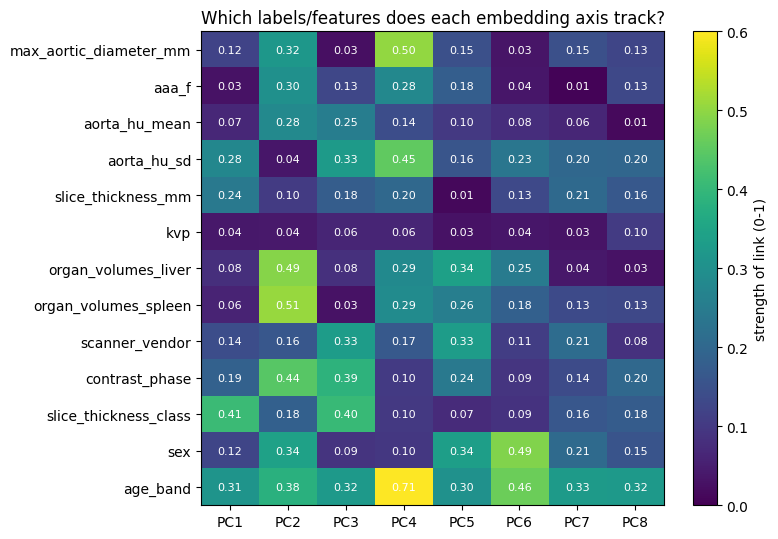

In [231]:
Zs = StandardScaler().fit_transform(D[emb_cols].to_numpy())
nc = int(max(2, min(32, len(D) - 3)))
P = PCA(nc, random_state=0).fit_transform(Zs)
cvg = StratifiedGroupKFold(5, shuffle=True, random_state=0)

def predictability(col):
    y = D[col].fillna("MISSING").astype(str)
    y = y.where(y.map(y.value_counts()) >= 10)
    m = y.notna().to_numpy()
    if m.sum() < 25 or y[m].nunique() < 2: return None
    try:
        acc = cross_val_score(LogisticRegression(max_iter=2000), P[m], y[m], groups=lab_D[m], cv=cvg, scoring="balanced_accuracy").mean()
    except Exception:
        return None
    return {"balanced_accuracy": float(acc), "chance": float(1 / y[m].nunique())}

pred_tab = {c: predictability(c) for c in ["scanner_vendor", "contrast_phase", "slice_thickness_class", "sex", "age_band", "aaa"] if c in D}
pred_tab = {k: v for k, v in pred_tab.items() if v}
cont = {}
for c in ["max_aortic_diameter_mm", "aorta_hu_mean", "slice_thickness_mm"]:
    if c in D and D[c].notna().sum() > 25:
        try: cont[c] = float(cross_val_score(Ridge(alpha=100), P, D[c].fillna(D[c].median()), groups=lab_D, cv=GroupKFold(min(5, len(set(lab_D)))), scoring="r2").mean())
        except Exception: pass
print("How well each variable can be read back from the embeddings (balanced accuracy vs chance):")
print(pd.DataFrame(pred_tab).T.round(2).to_string())
print("\nR2 for continuous variables:", {k: round(v, 2) for k, v in cont.items()})

acq = [pred_tab[c]["balanced_accuracy"] - pred_tab[c]["chance"] for c in ["scanner_vendor", "contrast_phase", "slice_thickness_class"] if c in pred_tab]
dis = (pred_tab["aaa"]["balanced_accuracy"] - pred_tab["aaa"]["chance"]) if "aaa" in pred_tab else np.nan
if acq and not np.isnan(dis):
    if np.mean(acq) > dis + 0.10:
        finding("Embeddings", "yellow", f"In this hospital the embeddings encode scanner/protocol information (+{np.mean(acq):.2f} above chance) more strongly than the aneurysm label (+{dis:.2f}); a model on top of them could learn acquisition shortcuts.", acquisition_signal=np.mean(acq), aaa_signal=dis)
    else:
        finding("Embeddings", "info", f"The embeddings carry aneurysm information (+{dis:.2f} above chance) at least as strongly as scanner/protocol information (+{np.mean(acq):.2f}).")

# ---- which embedding axes track which labels/features ----
num_vars = [v for v in ["max_aortic_diameter_mm", "aaa_f", "aorta_hu_mean", "aorta_hu_sd", "slice_thickness_mm", "kvp",
                        "organ_volumes_liver", "organ_volumes_spleen"] if v in D]
cat_vars = [v for v in ["scanner_vendor", "contrast_phase", "slice_thickness_class", "sex", "age_band"] if v in D]

def eta(x, g):
    g = g.fillna("MISSING"); m = x.notna(); x, g = x[m], g[m]
    tot = ((x - x.mean()) ** 2).sum()
    return float(np.sqrt(sum(len(v) * (v.mean() - x.mean()) ** 2 for _, v in x.groupby(g)) / tot)) if tot > 0 else np.nan

pcs = [f"PC{i + 1}" for i in range(min(8, P.shape[1]))]
Pdf = pd.DataFrame(P[:, :len(pcs)], columns=pcs)
assoc = {v: [abs(spearmanr(Pdf[c], D[v], nan_policy="omit")[0]) for c in pcs] for v in num_vars}
assoc.update({v: [eta(Pdf[c], D[v]) for c in pcs] for v in cat_vars})
Aassoc = pd.DataFrame(assoc, index=pcs).T
fig, ax = plt.subplots(figsize=(8, 5.5))
im = ax.imshow(Aassoc.to_numpy(float), cmap="viridis", vmin=0, vmax=0.6, aspect="auto")
ax.set_xticks(range(len(pcs))); ax.set_xticklabels(pcs); ax.set_yticks(range(len(Aassoc))); ax.set_yticklabels(Aassoc.index)
for (i, j), v in np.ndenumerate(Aassoc.to_numpy(float)): ax.text(j, i, "" if np.isnan(v) else f"{v:.2f}", ha="center", va="center", color="w", fontsize=8)
plt.colorbar(im, label="strength of link (0-1)"); ax.set_title("Which labels/features does each embedding axis track?")
plt.tight_layout(); show(fig, "04_embedding_links")
RESULTS["embedding_analysis"] = {"readable_from_embeddings": pred_tab, "r2_continuous": cont, "pc_association": Aassoc.round(3).reset_index().rename(columns={"index": "variable"})}

## 7. (Optional) Aorta shape and outline quality with pykarambola

**Off by default** (`USE_SHAPE = False`) because turning masks into meshes and shape features takes time. Turn it on in the CONFIG cell by giving either

* `SHAPE_FEATURES_FILE`: a `karambola_features.parquet` you already made, or
* `MASK_DIR`: the folder of `*_aorta.nii.gz` masks (needs `nibabel`, `scikit-image`, `trimesh`, `pykarambola`).

**What it tells a clinician** (in plain words):
* Is each outline **one clean piece**, or does it have **holes or loose fragments**? (Euler characteristic, 2 = one clean closed surface.)
* What is the outline's **average width** (4 x volume / surface area, a rough tube-width), and does the recorded **maximum diameter** make sense next to it? A maximum diameter smaller than the average width is not physically sensible.
* Do the outline shapes look like the **reference hospital's**?
* When the model's outline overlaps the expert outline poorly (**low Dice**), is the diameter error larger?

> **Which masks?** I do not know from the files whether `masks/` holds the expert (reference) outlines or the model's own. These checks describe whichever masks you point to: for the reference masks they check the **ground truth**; for the model's masks they check the **model's segmentation**.

In [232]:
def _shape_one(mask_path, smooth_iters=10):
    """One mask -> mesh -> pykarambola features + simple outline facts (same recipe as the mesh notebook)."""
    import nibabel as nib, trimesh
    from scipy import ndimage
    from skimage import measure
    mask_path = Path(mask_path); case_id = mask_path.name.replace("_aorta.nii.gz", "").replace(".nii.gz", "")
    try:
        img = nib.load(str(mask_path)); mask = np.asarray(img.dataobj) > 0
        if mask.sum() == 0: return {"case_id": case_id, "status": "empty mask"}
        lab, n_pieces = ndimage.label(mask)
        sizes = np.bincount(lab.ravel())[1:]
        verts, faces, _, _ = measure.marching_cubes(np.pad(mask, 1).astype(np.uint8), level=0.5)
        verts = nib.affines.apply_affine(img.affine, verts - 1)
        mesh = trimesh.Trimesh(verts, faces, process=True)
        if smooth_iters: trimesh.smoothing.filter_taubin(mesh, iterations=smooth_iters)
        v = np.asarray(mesh.vertices, dtype=np.float64); f = np.asarray(mesh.faces, dtype=np.int64)
        row = {"case_id": case_id, "status": "ok", "watertight": bool(mesh.is_watertight), "n_pieces": int(n_pieces),
               "largest_piece_share": float(sizes.max() / sizes.sum())}
        try:
            import pykarambola as pk
            res = pk.minkowski_tensors(v - v.mean(axis=0), f, compute="standard")
            for key, val in res.items():
                arr = np.asarray(val, dtype=float)
                if arr.ndim == 0: row[key] = float(arr)
                else:
                    for idx, x in np.ndenumerate(arr): row[f"{key}_{'_'.join(map(str, idx))}"] = float(x)
        except ImportError:
            row["status"] = "ok (no pykarambola: only basic outline facts)"
        return row
    except Exception as e:
        return {"case_id": case_id, "status": f"error: {e}"}

def compute_shape_features(mask_dir, only_ids=None):
    from joblib import Parallel, delayed
    files = sorted(Path(mask_dir).glob("*_aorta.nii.gz"))
    if only_ids is not None: files = [f for f in files if f.name.replace("_aorta.nii.gz", "") in only_ids]
    print(f"computing shape features for {len(files)} masks ...")
    return pd.DataFrame(Parallel(n_jobs=N_JOBS, verbose=5)(delayed(_shape_one)(f) for f in files))

def add_shape_columns(S):
    S = S.copy()
    if "w300" in S: S["chi"] = 3 * S["w300"] / (2 * np.pi)                       # Euler characteristic: 2 = one closed surface
    if "w000" in S and "w100" in S:
        S["volume_ml"] = S["w000"] / 1000.0
        S["avg_width_mm"] = 4 * S["w000"] / (3 * S["w100"])                       # ~ tube width = 4 x volume / surface area
    return S

shape_df, SHAPE = None, {"available": False, "reason": None, "comments": []}
if not USE_SHAPE:
    SHAPE["reason"] = "USE_SHAPE is False (shape analysis skipped)"
elif SHAPE_FEATURES_FILE and Path(SHAPE_FEATURES_FILE).exists():
    shape_df = pd.read_parquet(SHAPE_FEATURES_FILE); SHAPE["source"] = str(SHAPE_FEATURES_FILE)
elif MASK_DIR and Path(MASK_DIR).exists():
    shape_df = compute_shape_features(MASK_DIR, only_ids=set(D["case_id"]))
    shape_df.to_parquet(OUT_DIR / f"{HOSPITAL_NAME}_shape_features.parquet", index=False); SHAPE["source"] = str(MASK_DIR)
else:
    SHAPE["reason"] = "USE_SHAPE is True but neither SHAPE_FEATURES_FILE nor MASK_DIR exists"
print("shape analysis:", SHAPE["reason"] or f"using {SHAPE.get('source')}")

shape analysis: USE_SHAPE is False (shape analysis skipped)


In [233]:
def shape_comment(sev, text, **ev):
    SHAPE["comments"].append({"severity": sev, "text": text}); finding("Segmentation shape", sev, text, **ev)

# Dice needs no shape features: how well does the model's outline overlap the expert's?
dice_new, dice_ref = perf["new"]["outline_dice"], perf["reference"]["outline_dice"]
if dice_new:
    sev = "red" if dice_new["median"] < 0.85 else ("yellow" if dice_new["median"] < 0.90 or dice_new["share_below_0.90"] > 0.10 else "ok")
    SHAPE["dice"] = dice_new
    shape_comment(sev, f"The model's aorta outline overlaps the expert outline well in most scans (median Dice {dice_new['median']:.2f}, reference {dice_ref.get('median', float('nan')):.2f}); {dice_new['share_below_0.90']:.0%} of scans are below 0.90.")
    low = D["pred_aorta_dice"] < 0.90
    if 3 <= low.sum() < len(D) - 3 and D.loc[low, "base_err"].notna().sum() >= 3:
        e_low, e_hi = D.loc[low, "base_err"].abs().mean(), D.loc[~low, "base_err"].abs().mean()
        shape_comment("yellow" if e_low > 2 * e_hi and e_low > 2 else "info", f"Scans with a poor outline (Dice < 0.90) have an average diameter error of {e_low:.1f} mm, versus {e_hi:.1f} mm for the rest.")

if shape_df is not None:
    if "status" in shape_df: shape_df = shape_df[shape_df["status"].astype(str).str.startswith("ok")]
    S = add_shape_columns(shape_df.drop_duplicates("case_id"))
    S = D[["case_id", "max_aortic_diameter_mm", "pred_max_diameter_mm", "pred_aorta_dice", "aaa"]].merge(S, on="case_id", how="inner")
    SHAPE["available"] = True; SHAPE["n_masks"] = int(len(S)); SHAPE["share_of_scans_with_mask"] = float(len(S) / len(D))
    if len(S) < 10:
        shape_comment("yellow", f"Only {len(S)} scans have shape features; shape comments are not reliable.")
    else:
        # 1. one clean piece?
        if "chi" in S:
            clean_ = (S["chi"] - 2).abs() < 0.1
            bad_ids = S.loc[~clean_, "case_id"].tolist()
            SHAPE["share_clean_outline"] = float(clean_.mean()); SHAPE["outlines_to_review"] = bad_ids[:25]
            sev = "red" if (1 - clean_.mean()) > 0.15 else ("yellow" if (1 - clean_.mean()) > 0.05 else "ok")
            shape_comment(sev, f"{clean_.mean():.0%} of aorta outlines are one clean closed piece; {(~clean_).sum()} have holes or loose fragments and should be reviewed before their measurements are trusted.", ids=bad_ids[:25])
        if "n_pieces" in S:
            frag = (S["n_pieces"] > 1)
            SHAPE["share_multiple_pieces"] = float(frag.mean())
            if frag.mean() > 0.05: shape_comment("yellow", f"{frag.mean():.0%} of masks consist of more than one separate piece (loose specks or a broken aorta).")
        if "watertight" in S:
            SHAPE["share_watertight"] = float(S["watertight"].astype(bool).mean())
        # 2. does the recorded maximum diameter make sense next to the outline's average width?
        if "avg_width_mm" in S:
            m = S["max_aortic_diameter_mm"].notna() & S["avg_width_mm"].notna()
            rho = float(spearmanr(S.loc[m, "avg_width_mm"], S.loc[m, "max_aortic_diameter_mm"])[0]) if m.sum() > 5 else np.nan
            too_small = m & (S["max_aortic_diameter_mm"] < 0.8 * S["avg_width_mm"])
            SHAPE["spearman_width_vs_label"] = rho; SHAPE["n_label_smaller_than_outline_width"] = int(too_small.sum())
            SHAPE["label_smaller_than_width_ids"] = S.loc[too_small, "case_id"].tolist()[:25]
            if not np.isnan(rho):
                sev = "yellow" if rho < 0.3 else "ok"
                shape_comment(sev, f"The outline's average width tracks the recorded maximum diameter {'only weakly' if rho < 0.3 else 'reasonably'} (rank correlation {rho:.2f}). "
                                   + ("The masks and the labels may not describe the same part of the aorta." if rho < 0.3 else "Outlines and labels broadly agree."))
            if too_small.sum():
                shape_comment("yellow", f"In {too_small.sum()} scans the recorded maximum diameter is smaller than the outline's own average width, which cannot be right for a tube: the label or the outline is probably wrong.", ids=SHAPE["label_smaller_than_width_ids"])
        # 3. shapes vs the reference hospital
        if REF_SHAPE_FEATURES_FILE and Path(REF_SHAPE_FEATURES_FILE).exists():
            Sr = add_shape_columns(pd.read_parquet(REF_SHAPE_FEATURES_FILE))
            for c, nice in [("avg_width_mm", "average width"), ("volume_ml", "volume")]:
                if c in S and c in Sr:
                    lo, hi = Sr[c].quantile([0.01, 0.99]); out_ = float(((S[c] < lo) | (S[c] > hi)).mean())
                    SHAPE[f"share_outside_reference_{c}"] = out_
                    if out_ > 0.15: shape_comment("yellow", f"{out_:.0%} of outlines have a {nice} outside the range seen at the reference hospital.")
        # 4. picture
        fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
        if "avg_width_mm" in S:
            ax[0].scatter(S["avg_width_mm"], S["max_aortic_diameter_mm"], s=14, c=np.where(S["aaa"], "r", "tab:blue"), alpha=0.7)
            lim = [0, max(S["avg_width_mm"].max(), S["max_aortic_diameter_mm"].max()) + 3]; ax[0].plot(lim, lim, "k--", lw=1)
            ax[0].set_xlabel("outline average width (mm)"); ax[0].set_ylabel("recorded max diameter (mm)"); ax[0].set_title("Outline width vs recorded diameter (red = AAA)")
        if "chi" in S:
            S["chi"].round().value_counts().sort_index().plot.bar(ax=ax[1]); ax[1].set_title("Euler characteristic of each outline (2 = one clean closed piece)")
        plt.tight_layout(); show(fig, "05_shape")
        print(pd.Series({k: v for k, v in SHAPE.items() if not isinstance(v, (list, dict))}).to_string())
        if "chi" in S: D = D.merge(S[["case_id", "chi"]].rename(columns={"chi": "k_chi"}).drop_duplicates("case_id"), on="case_id", how="left")
else:
    print("(no shape features loaded; only the Dice comments above are available)")
RESULTS["segmentation_shape"] = SHAPE

[OK]     The model's aorta outline overlaps the expert outline well in most scans (median Dice 0.98, reference 0.98); 4% of scans are below 0.90.
(no shape features loaded; only the Dice comments above are available)


## 8. Go-live triggers, summary, and the JSON file

The trigger table reuses `monitor.py`, so the one-off test and the monthly go-live reports use exactly the same rules.

In [234]:
trig = monitor.evaluate(D, prof)
print(trig[["group", "trigger", "value", "status"]].assign(value=trig.apply(lambda r: monitor.fmt(r["value"], r["kind"]), axis=1)).to_string(index=False))

n_red = int((trig["status"] == "RED").sum()) + sum(f["severity"] == "red" for f in FINDINGS)
n_yel = int((trig["status"] == "YELLOW").sum()) + sum(f["severity"] == "yellow" for f in FINDINGS)
if n_red:   verdict = "REVIEW NEEDED: do not rely on this model at this hospital until the red items are resolved."
elif n_yel: verdict = "PROCEED WITH CARE: usable, but monitor the yellow items closely."
else:       verdict = "LOOKS COMPARABLE: no alerts against the reference hospital."
print("\n" + "=" * 100 + f"\nVERDICT for {HOSPITAL_NAME} (compared with {REFERENCE_NAME}): {verdict}\n" + "=" * 100)
order = {"red": 0, "yellow": 1, "ok": 2, "info": 3}
for sev, title in [("red", "ACT BEFORE RELYING ON THE MODEL"), ("yellow", "WATCH"), ("ok", "LOOKS FINE"), ("info", "GOOD TO KNOW")]:
    items = [f for f in FINDINGS if f["severity"] == sev]
    if items:
        print(f"\n--- {title} ---")
        for f in items: print(f"  * [{f['area']}] {f['text']}")

                                 group                                      trigger   value status
Model outputs (no ground truth needed)                               No-answer rate    1.2%  GREEN
Model outputs (no ground truth needed)          Change in share of scans called AAA 0.9 pts  GREEN
Model outputs (no ground truth needed)                Shift in predicted aorta size 0.10 SD  GREEN
                 Patients and scanners                            Scanner brand mix    6.0%  GREEN
                 Patients and scanners                           Contrast phase mix    4.0%  GREEN
                 Patients and scanners                          Slice thickness mix    0.3%  GREEN
                 Patients and scanners                                      Sex mix    0.2%  GREEN
                 Patients and scanners                                      Age mix   10.3%  GREEN
                 Patients and scanners               Shift in aorta brightness (HU) 0.20 SD  GREEN
          

In [235]:
result = {
    "meta": {"hospital": HOSPITAL_NAME, "reference": REFERENCE_NAME, "generated_at": datetime.now().isoformat(timespec="seconds"),
             "n_scans": len(D), "cutoff_mm": AAA_CUTOFF_MM, "near_duplicate_similarity": SIM_DUP,
             "shape_analysis_used": bool(SHAPE.get("available"))},
    "verdict": {"text": verdict, "n_red": n_red, "n_yellow": n_yel},
    "files": RESULTS["files"],
    "dataset_description": RESULTS["dataset_description"],
    "integrity_checks": RESULTS["integrity"],
    "shift_vs_reference": RESULTS["shift_vs_reference"],
    "model_performance": RESULTS["model_performance"],
    "embedding_analysis": RESULTS["embedding_analysis"],
    "segmentation_shape": RESULTS["segmentation_shape"],
    "triggers": trig.drop(columns=["worse"]),
    "findings": FINDINGS,
    "figures": FIGS,
}
json_path = OUT_DIR / f"{HOSPITAL_NAME}_test_results.json"
with open(json_path, "w") as fh: json.dump(clean(result), fh, indent=2)
html_path = OUT_DIR / f"{HOSPITAL_NAME}_report.html"
html_path.write_text(monitor.build_report(trig, HOSPITAL_NAME, "one-time test", len(D), REFERENCE_NAME))

back = json.load(open(json_path))
print(f"saved {json_path}  ({json_path.stat().st_size / 1024:.0f} KB, top-level keys: {list(back)})")
print(f"saved {html_path}")
display(HTML(html_path.read_text()))

saved hospital_test_output/hospital_g_test_results.json  (39 KB, top-level keys: ['meta', 'verdict', 'files', 'dataset_description', 'integrity_checks', 'shift_vs_reference', 'model_performance', 'embedding_analysis', 'segmentation_shape', 'triggers', 'findings', 'figures'])
saved hospital_test_output/hospital_g_report.html


## 9. Export for Slicepoint

Writes `<hospital>_slicepoint.json` in the format Slicepoint loads: one row per scan, the five checks (`repeats`, `scanning`, `labels`, `accuracy`, `patients`) with a status of Problem / Watch / OK, and the model performance numbers. The last lines check the file against that format and print **COMPATIBLE** or list what is wrong.

Run this after section 8, because it reads `FINDINGS`, `RESULTS`, `D` and `lab_D`.

In [236]:
# ===================== 9. Export for Slicepoint =====================
TEAM_DICE = None   # leave None; Umang's image file provides our own Dice

def _num(v):  return None if pd.isna(v) else round(float(v), 2)
def _txt(v):  return None if pd.isna(v) else str(v)
def _flag(v): return None if pd.isna(v) else bool(v)

# ---- scans: one row per scan, from D and the real-person groups lab_D ----
scans = []
for i, r in D.iterrows():
    scans.append({
        "id": str(r["case_id"])[:8],
        "personGroup": f"p{lab_D[i]}",
        "sex": _txt(r.get("sex")),
        "age_band": _txt(r.get("age_band")),
        "scanner_vendor": _txt(r.get("scanner_vendor")),
        "contrast_phase": _txt(r.get("contrast_phase")),
        "slice_thickness_class": _txt(r.get("slice_thickness_class")),
        "aaa_size_class": _txt(r.get("aaa_size_class")),
        "aaa": _flag(r.get("aaa")),
        "referenceDiameterMm": _num(r.get("max_aortic_diameter_mm")),
        "aiDiameterMm": _num(r.get("pred_max_diameter_mm")),
        "aiAaa": _flag(r.get("pred_aaa_f")),      # null = the AI gave no answer
    })

# ---- findings: our FINDINGS areas -> Slicepoint's 5 checks ----
AREA_TO_CHECK = {
    "Repeat patients": "repeats", "Leakage": "repeats",
    "Scan content": "scanning", "Impossible values": "scanning", "Embeddings": "scanning",
    "Labelling": "labels", "Labelling vs model": "labels",
    "AAA model": "accuracy", "Subgroups": "accuracy", "Silent failures": "accuracy",
    "Measurement outliers": "accuracy", "Segmentation shape": "accuracy",
}   # "Files" and any 'info' items go to notes
PATIENT_WORDS = ["sex", "age", "prevalence", "aorta diameter"]
STATUS = {"red": "Problem", "yellow": "Watch", "ok": "OK"}
RANK = {"Problem": 0, "Watch": 1, "OK": 2}

def _check(f):
    if f["area"] == "Patients & scanners":
        return "patients" if any(w in f["text"].lower() for w in PATIENT_WORDS) else "scanning"
    return AREA_TO_CHECK.get(f["area"])

by_check, notes = {}, []
for f in FINDINGS:
    c, s = _check(f), STATUS.get(f["severity"])
    if c is None or s is None:
        notes.append(f["text"]); continue
    by_check.setdefault(c, []).append((s, f["text"]))

findings = []
for c, items in by_check.items():
    worst = min(items, key=lambda x: RANK[x[0]])[0]
    findings.append({"check": c, "status": worst,
                     "sentence": " ".join([t for s, t in items if s == worst][:2])})

# ---- performance and Dice, straight from our results ----
perf = RESULTS["model_performance"]["new"]
dice_mean = perf.get("outline_dice", {}).get("mean")

sp = {
    "fileType": "hospital_data",
    "hospitalName": HOSPITAL_NAME.replace("_", " ").title(),
    "scans": scans,
    "findings": findings,
    "notes": notes,
    "performance": {
        "aaa_missing_as_wrong": perf.get("aaa_call_missing_as_wrong", {}),
        "aaa_when_answered":    perf.get("aaa_call_when_answered", {}),
        "diameter":             perf.get("diameter", {}),
        "dice":                 perf.get("outline_dice", {}),
    },
}
if TEAM_DICE is not None or dice_mean is not None:
    sp["dice"] = {"average": round(float(TEAM_DICE if TEAM_DICE is not None else dice_mean), 3),
                  "note": "Our team's segmentation." if TEAM_DICE is not None else "Baseline model Dice."}

sp = clean(sp)   # numpy -> python, NaN -> null
sp_path = OUT_DIR / f"{HOSPITAL_NAME}_slicepoint.json"
sp_path.write_text(json.dumps(sp, allow_nan=False))

# ---- compatibility check: does the file match what Slicepoint expects? ----
SCAN_KEYS = ["id", "personGroup", "sex", "age_band", "scanner_vendor", "contrast_phase", "slice_thickness_class",
             "aaa_size_class", "aaa", "referenceDiameterMm", "aiDiameterMm", "aiAaa"]
CHECKS = {"repeats", "scanning", "labels", "accuracy", "patients"}
back = json.loads(sp_path.read_text())
problems = []
if back.get("fileType") != "hospital_data": problems.append("fileType must be 'hospital_data'")
if not back.get("hospitalName"):            problems.append("hospitalName is empty")
if not back.get("scans"):                   problems.append("no scans exported")
for k in ["scans", "findings", "notes", "performance"]:
    if k not in back: problems.append(f"missing top-level key '{k}'")
bad = [s["id"] for s in back["scans"] if list(s) != SCAN_KEYS]
if bad: problems.append(f"{len(bad)} scans have wrong/missing keys, e.g. {bad[:3]}")
if len(back["scans"]) != len(D): problems.append(f"scan count {len(back['scans'])} != {len(D)} in D")
ids = [s["id"] for s in back["scans"]]
if len(set(ids)) != len(ids): problems.append("short ids (first 8 chars of case_id) are not unique")
for f in back["findings"]:
    if f["check"] not in CHECKS: problems.append(f"unknown check '{f['check']}'")
    if f["status"] not in RANK:  problems.append(f"unknown status '{f['status']}'")
    if not f["sentence"]:        problems.append(f"empty sentence for '{f['check']}'")
no_finding = CHECKS - {f["check"] for f in back["findings"]}

# ---- quick self-check ----
print(f"saved {sp_path}  ({sp_path.stat().st_size / 1024:.0f} KB)")
print(f"  hospitalName: {back['hospitalName']}")
print(f"  scans: {len(back['scans'])}, people: {len(set(lab_D))}")
print(f"  sex mix: {pd.Series([s['sex'] for s in back['scans']]).value_counts(dropna=False).to_dict()}")
print(f"  AI gave no AAA answer for: {sum(s['aiAaa'] is None for s in back['scans'])} scans")
print(f"  findings: {[(f['check'], f['status']) for f in back['findings']]}")
if no_finding: print(f"  checks with no finding (Slicepoint will show nothing for them): {sorted(no_finding)}")
print(f"  notes (not mapped to a check): {len(back['notes'])}")
print(f"  sensitivity (missing = wrong): {back['performance']['aaa_missing_as_wrong'].get('sens')}")
print("  COMPATIBLE with Slicepoint format" if not problems else "  NOT COMPATIBLE:\n    - " + "\n    - ".join(problems))

try:
    from google.colab import files
    files.download(str(sp_path))
except ImportError:
    pass   # not in Colab: the file is in OUT_DIR

saved hospital_test_output/hospital_g_slicepoint.json  (24 KB)
  hospitalName: Hospital G
  scans: 80, people: 80
  sex mix: {'M': 45, 'F': 35}
  AI gave no AAA answer for: 1 scans
  findings: [('repeats', 'OK'), ('labels', 'Watch'), ('scanning', 'OK'), ('accuracy', 'Watch')]
  checks with no finding (Slicepoint will show nothing for them): ['patients']
  notes (not mapped to a check): 3
  sensitivity (missing = wrong): 1.0
  COMPATIBLE with Slicepoint format
